# iEEG processing


## 📦 Imports

In [1]:
import mindmap as mm

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `ieeg`: Raw iEEGs

🎚️ **<font color=pink>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id
- `samp`: EEG sample

In [2]:
# ------------- Parameters ---------------
fconfig = "../../data/config.yml"
subject = "intra-12"
# ----------------------------------------

reader = mm.io.TutoReader(fconfig)
data   = reader(subject, "ieeg")

DATA SUMMARY
Dataset: tuto
Subject: intra-12
Task: None
Run: None
Retrieved objects:
- ieeg
Missing objects:


Using matplotlib as 2D backend.


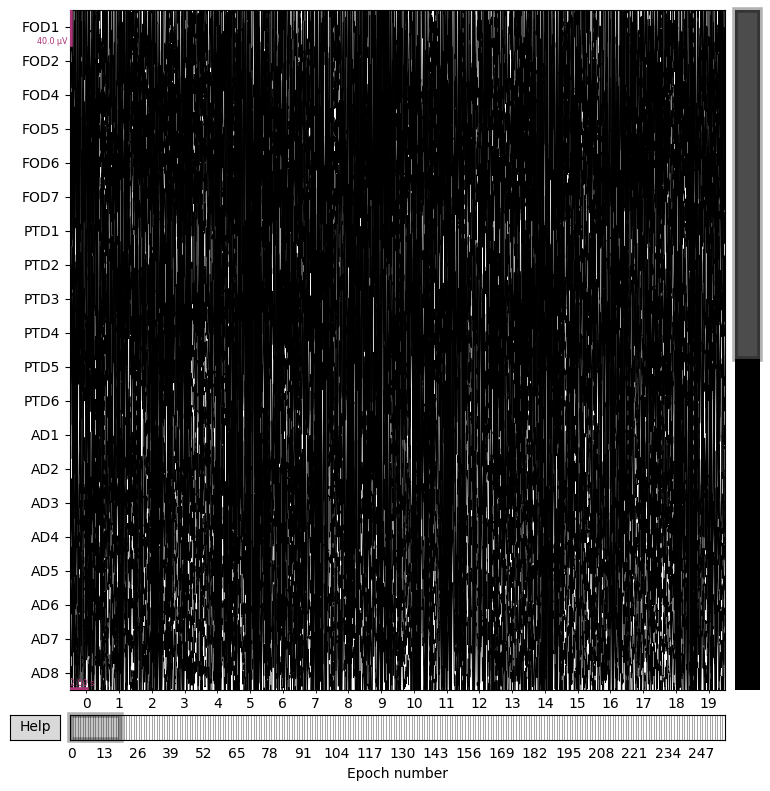

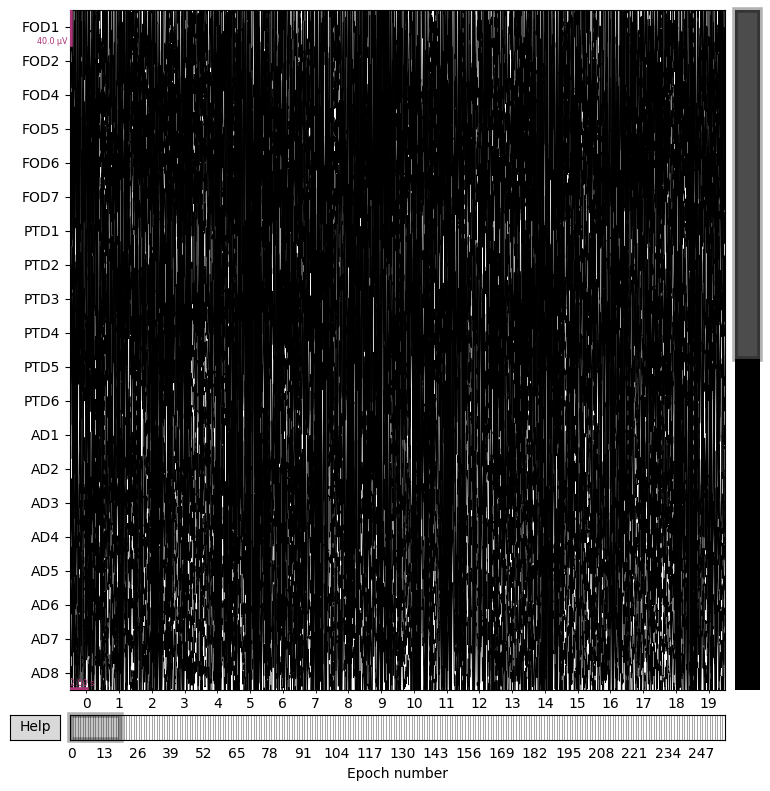

In [3]:
data["ieeg"].plot()

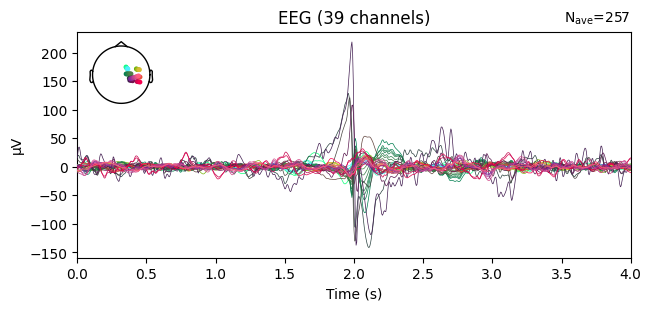

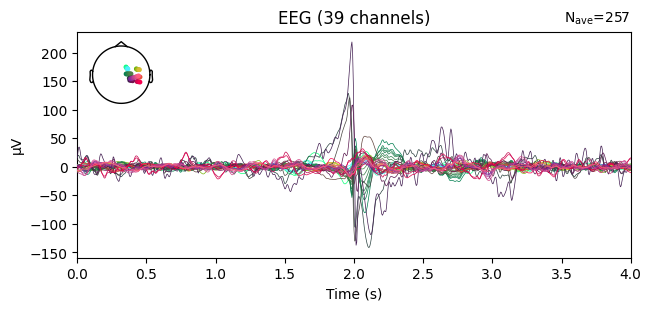

In [4]:
evoked = data["ieeg"].average()
evoked.plot()

# iEEG 3D visualization

## 📦 Imports

In [1]:
import mindmap as mm

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `iave`: Averaged iEEG
- `src`: Source space.

🎚️ **<font color=pink>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id
- `task`: task

In [ ]:
# ------------- Parameters ---------------
fconfig = "../../data/config.yml"
subject = "intra-12"
task    = "spk"
# ----------------------------------------

reader = mm.io.TutoReader(fconfig)
data   = reader(subject, "src-raw", "iave", task=task)

NameError: name 'mm' is not defined

In [ ]:
mm.viz.plot_ieeg()

In [ ]:
# in core.metric.py

import numpy as np
from scipy.spatial.distance import cdist
import mne
import mindmap as mm

# to put in mm.core.metrics (math layer)

def calc_spatial_correlation(map_ref, map_est):
    """
    Pearson correlation between reference and estimated spatial maps.

    Ths function performs a vectorized calculation of the spatial correlation
    for each observation (e.g. timepoint or trial) independently.

    Parameters
    ----------
    map_ref: np.ndarray of shape (n_observations, n_channels)
        The ground truth of reference spatial maps (e.g., actual iEEG).

    map_est: np.ndarray of shape (n_observations, n_channels)
        The estimated spatial maps (e.g., virtual iEEG from EEG)

    Returns
    -------
    sp_cor: np.ndarray of shape (n_observations,)
        The spatial correlation coefficient for every observation.
        Returns 0 where a map has zero variance.
    """
    # ensure inputs are at least 2D: (n_observations, n_channels)
    # if input is (M,), it becomes (1,M)
    map_ref = np.atleast_2d(map_ref)
    map_est = np.atleast_2d(map_est)

    if map_ref.shape != map_est.shape:
        raise ValueError(f"Shape mismatch: map_ref {map_ref.shape} and map_est {map_est.shape} must be identical.")

    # center data
    ref_c = map_ref - map_ref.mean(axis=1, keepdims=True)
    est_c = map_est - map_est.mean(axis=1, keepdims=True)

    # cacluate correlation
    upper = np.sum(ref_c * est_c, axis=1)
    lower = np.sqrt(np.sum(ref_c**2, axis=1) * np.sum(est_c**2, axis=1))

    sp_cor = np.divide(upper, lower, out=np.zeros_like(upper), where=lower > 1e-12)
    
    return sp_cor if sp_cor.size > 1 else sp_cor[0]


def calc_pairwise_dist(array1, array2, output_type="scalar"):
    """
    Computes pairwise distances between points of two arrays. Displacements
    will point from array1 to array2.

    Parameters:
    ----------
    array1: np.ndarray
        Array of shape (N,D) or (N,)
    
    array2: np.ndarray
        Array of shape (N,D) or (N,)

    output_type: str
        'scalar' (Euclidean) or 'vector' (Displacement)

    Returns
    -------
    dist: np.ndarray
        If 'scalar': Array of shape (N,) containing L2 norms
        If 'vector': Array of shape (N,D) containing displacement vectors.
    """
    # Ensure inputs are numpy arrays
    a1 = np.atleast_2d(array1)
    a2 = np.atleast_2d(array2)

    # pairwise differences
    diff =  a2 - a1

    if output_type == "vector":
        return diff
    elif output_type == "scalar":
        return np.linalg.norm(diff, axis=1)
    else:
        raise ValueError("output_type must be 'scalar' or 'vector'")
    

def calc_spatial_dispersion_grova(map_est, dist_to_h):
    """
    Grova's Spatial Dispersion (SD): Spread of estimated activity
    relative to the ground-truth clinical focus (Set H).

    Parameters
    ----------
    map_est: np.ndarray of shape (n_observations, n_channels)
        The estimated spatial maps (e.g., virtual iEEG)

    dist_to_h: np.ndarray of shape (n_channels,)
        Minimum distance from each channel i to the closest channel
        j in the reference set H. (dist = 0 if channel i is in H).

    Returns
    -------
    sp_dis: np.ndarray of shape (n_observations,)
        Spatial dispersion (SD). Higher values indicate 'smearing'
        outside the clinical zone or localization error.
    """
    # ensure inputs are at least 2D: (n_observations, n_channels)
    # if input is (M,), it becomes (1,M)
    map_est = np.atleast_2d(map_est)

    # ensure dist_to_h is (1, n_channels) for broadcasting
    dist_to_h = np.atleast_2d(dist_to_h)

    # Energy (V^2)
    energy = map_est**2

    # compute dispersion
    numerator   = np.sum(dist_to_h * energy, axis=1)
    denominator = np.sum(energy, axis=1)

    dispersion = np.sqrt(np.divide(numerator, denominator, out=np.zeros_like(numerator), where=denominator > 1e-12))
    
    return dispersion if dispersion.size > 1 else dispersion[0]


def calc_ratio_spurious_activity(map_est, is_distant_mask):
    """
    Ratio of Spurious Activity (RSA) as per Grova et al.

    Parameters
    ----------
    map_est: np.ndarray of shape (n_observations, n_channels)
        The estimated potentials (V_MEG).
    is_distant_mask: np.ndarray of shape (n_channels,)
        Boolean mask or binary array (1/0) where 1 indicates the contact
        is > 10mm away from the reference set H.

    Returns
    -------
    rsa: np.ndarray of shape (n_observations,)
        The ratio of energy in distant contacts vs total energy.
    """
    # ensure inputs are at least 2D: (n_observations, n_channels)
    # if input is (M,), it becomes (1,M)
    map_est = np.atleast_2d(map_est)

    # energy (V^2)
    energy = map_est**2

    # energy in distant contacts (numerator)
    # we use the mask to zero out energy in contacts close to H.
    spurious_energy = np.sum(energy[:, is_distant_mask], axis=1)

    # Total energy across all contacts (denominator)
    total_energy = np.sum(energy, axis=1)

    # RSA = Sum(V^2_distant) / Sum(V^2_total)
    rsa = np.divide(spurious_energy, total_energy, out=np.zeros_like(spurious_energy), where=total_energy>1e-12)

    return rsa if rsa.size > 1 else rsa[0]


# to put in mm.core.utils

def get_spike_extent_mask(
    data : np.ndarray,
    perc_max_amp : float = 0.7
) -> np.ndarray:
    """
    Identifies the boolean mask of channels belonging to the 
    spatial extent of a peak event.

    Parameters
    ----------
    data: np.ndarray of shape (n_timepoints, n_variables)
        Input data.

    perc_max_amp: float
        Percentage of maximum amplitude for threshold. Value between 0 and 1.

    Returns
    -------
        np.ndarray of shape (n_channels)
            Boolean mask (True where channel is in extent)
    """
    # ensure inputs are at least 2D: (n_timepoints, n_variables)
    # if input is (M,), it becomes (1,M)
    data = np.atleast_2d(data)

    # 1. Find the gloabl peak in time
    # We find the peak row (time_idx) across the whole matrix
    peak_time_idx = np.unravel_index(np.argmax(np.abs(data)), data.shape)[0]

    # 2. Extract the spatial distribution at that specific peak time
    # Shape will be (n_variables,)
    spatial_vector = np.abs(data[peak_time_idx, :])

    # 3. Calculate the threshold for this specific spatial vector
    threshold = perc_max_amp * np.max(spatial_vector)

    # 4. Create boolean mask
    return spatial_vector >= threshold


def get_spurious_mask(
    extent_mask : np.ndarray,
    coord : np.ndarray,
    spurious_dist : float = 0.01,
) -> np.ndarray:
    """
    Identifies the boolean mask of channels belonging to the spurious area.

    Parameters
    ----------
    extent_mask: np.ndarray
        Boolean mask of channels in the reference set H.
    coord: np.ndarray of shape (N, 3)
        Coordinates of channels (if in meters, spurious_dist should be 0.01).
    spurious_dist: float
        Distance beyond which data is spurious (e.g., 10 for mm).
    
    Returns
    -------
    is_spurious: np.ndarray
        Boolean mask where True indicates a 'distant' channel.
    """
    # Distance between all channels and the channels in set H
    dist_matrix = mm.core.compute_distances(coord, coord[extent_mask])

    # minimum distance to any channel in the extent
    dist_to_h   = np.min(dist_matrix, axis=1)

    return dist_to_h > spurious_dist



# to put in mm.analysis.eeg.utils

def same_evoked(*args: mne.Evoked):
    """
    Checks if Evokeds have the same channels and timepoints.

    Parameters
    ----------
    args: mne.Evoked
        Any number of evokeds.
    """
    # reference (args[0])
    ch_ref   = args[0].ch_names
    pos_ref  = mm.analysis.eeg.get_ch_positions(args[0])
    time_ref = args[0].times

    # iterate through evokeds
    for a in args:
        if not np.all(ch_ref == a.ch_names):
            return False
        if not np.all(pos_ref == mm.analysis.eeg.get_ch_positions(a)):
            return False
        if not np.all(time_ref == a.times):
            return False
        
    return True


# to put in mm.analysis.eeg.metrics (Neuroscience layer)

def compute_spatial_correlation(
    evoked_ref : mne.Evoked,
    evoked_est : mne.Evoked,
    average    : bool = False,
) -> np.ndarray | float:
    """
    Computes spatial correlation between evoked objects.
    Assumes objects have the same channels and timepoints.

    Parameters
    ----------
    evoked_ref: mne.Evoked
        Reference activity (e.g. true iEEG)

    evoked_est: mne.Evoked
        Estimated activity (e.g. virtual iEEG)

    average: bool defaults to True
        Whether to compute average spatial correlation over time points.

    Returns
    -------
    sp_cor: float or np.ndarray of size (n_timepoints,)
        Average spatial correlation (if average is True) or spatial 
        correlation per timepoint.
    """
    if not same_evoked(evoked_ref, evoked_est):
        raise ValueError("Evokeds must have same channels and timepoints.")
    
    # extract data
    data_ref = evoked_ref.data
    data_est = evoked_est.data

    # spatial correlation
    sp_cor = calc_spatial_correlation(data_ref, data_est)

    return np.mean(sp_cor) if average else sp_cor
    
def compute_minimum_distance(
    evoked_ref : mne.Evoked,
    evoked_est : mne.Evoked,
    average    : bool = False,
) -> np.ndarray | float:
    """
    Computes the minimum euclidean distance between the maximum channel
    value of the reference and the maximum channel value of the 
    estimated.

    Parameters
    ----------
    evoked_ref: mne.Evoked
        Reference activity (e.g. true iEEG)

    evoked_est: mne.Evoked
        Estimated activity (e.g. virtual iEEG)

    average: bool defaults to True
        Whether to compute average spatial correlation over time points.

    Returns
    -------
    dmin: float or np.ndarray of size (n_timepoints,)
        Minimum euclidean distance between channels with maximum
        activity.
    """
    if not same_evoked(evoked_ref, evoked_est):
        raise ValueError("Evokeds must have same channels and timepoints.")
    
    # extract data
    ch_pos   = mm.analysis.eeg.get_ch_positions(evoked_ref)     # (n_channels, 3)
    data_ref = evoked_ref.data                                  # (n_channels, n_timepoints)
    data_est = evoked_est.data

    # maximum channels
    ch_ref = ch_pos[np.argmax(data_ref, axis=0)]
    ch_est = ch_pos[np.argmax(data_est, axis=0)]

    # distance
    dist = calc_pairwise_dist(ch_ref, ch_est)

    return np.mean(dist) if average else dist


def compute_spatial_dispersion(
    evoked_est          : mne.Evoked,
    true_spatial_extent : list[str] | float = 0.7,
    evoked_ref          : mne.Evoked | None = None,
    average             : bool = False,
) -> np.ndarray:
    """
    Computes Spatial Dispersion (SD) as defined by Grova et al.
    
    Parameters
    ----------
    evoked_est: mne.Evoked
        Estimated activity (e.g. virtual iEEG)

    true_spatial_extent: list[str]
        Name of channels belonging to spatial extent or percentile to
        threshold channels belonging to extent.

    evoked_ref: mne.Evoked
        Reference activity (e.g. true iEEG)

    average: bool defaults to True
        Whether to compute average spatial dispersion over time points.

    Returns
    -------
    sp_ds: float or np.ndarray of size (n_timepoints,)
        Spatial dispersion or averaged spatial dispersion.
        
    """
    
    # 1. Coordinate and Estimation data extraction
    data_est = evoked_est.data.T
    ch_pos   = mm.analysis.eeg.get_ch_positions(evoked_est)

    # 2. Determine Set H Indices
    if isinstance(true_spatial_extent, (float, int)):
        # automatic mode
        if evoked_ref is None:
            raise ValueError(
                "evoked_ref must be provided when true_spatial_extent is a float "
                "to calculate the automatic spike extent."
            )
        
        # check consistency
        if not same_evoked(evoked_ref, evoked_est):
            raise ValueError("evoked_ref and evoked_est must have same channels/timepoints.")
        
        extent_mask = get_spike_extent_mask(evoked_ref.data.T, perc_max_amp=true_spatial_extent)

    else:
        # manual mode
        extent_mask = np.isin(evoked_est.ch_names, true_spatial_extent)
        
    if extent_mask.sum() == 0:
        raise ValueError("Set H (true_spatial_extent) is empty. Check channel names or threshold.")

    ch_ref_coords = ch_pos[extent_mask]

    # 3. Compute distance to set H
    dist_matrix = mm.core.metric.compute_distances(ch_pos, ch_ref_coords)    # (n_channels, size_extent)
    dist_to_h   = np.min(dist_matrix, axis=1)                                # (n_channels,)

    # compute spatial dispersion
    sp_dis = calc_spatial_dispersion_grova(data_est, dist_to_h)

    return np.mean(sp_dis) if average else sp_dis


def compute_ratio_spurious(
        evoked_est : mne.Evoked,
        true_spatial_extent : list[str] | float = 0.7,
        spurious_dist: float = 0.01,
        evoked_ref : mne.Evoked = None,
        average : bool = False,
):
    """
    Computes ratio of spurious activity as defined by Grova et al.
    
    Parameters
    ----------
    evoked_est: mne.Evoked
        Estimated activity (e.g. virtual iEEG)

    true_spatial_extent: list[str]
        Name of channels belonging to spatial extent or percentile to
        threshold channels belonging to extent.

    evoked_ref: mne.Evoked
        Reference activity (e.g. true iEEG)

    average: bool defaults to True
        Whether to compute average spatial dispersion over time points.

    Returns
    -------
    sp_ds: float or np.ndarray of size (n_timepoints,)
        Spatial dispersion or averaged spatial dispersion.
        
    """
    # 1. Coordinate and Estimation data extraction
    data_est = evoked_est.data.T
    ch_pos   = mm.analysis.eeg.get_ch_positions(evoked_est)

    # 2. Determine Set H Indices
    if isinstance(true_spatial_extent, (float, int)):
        # automatic mode
        if evoked_ref is None:
            raise ValueError(
                "evoked_ref must be provided when true_spatial_extent is a float "
                "to calculate the automatic spike extent."
            )
        
        # check consistency
        if not same_evoked(evoked_ref, evoked_est):
            raise ValueError("evoked_ref and evoked_est must have same channels/timepoints.")
        
        extent_mask = get_spike_extent_mask(evoked_ref.data.T, perc_max_amp=true_spatial_extent)

    else:
        # manual mode
        extent_mask = np.isin(evoked_est.ch_names, true_spatial_extent)
        
    # 3. Determine spurious mask
    is_distant_mask = get_spurious_mask(extent_mask, ch_pos, spurious_dist = spurious_dist)

    # 4. Compute ratio of spurious activity
    rsa = calc_ratio_spurious_activity(data_est, is_distant_mask)

    return np.mean(rsa) if average else rsa


def compute_grova_metrics(
    evoked_ref : mne.Evoked,
    evoked_est : mne.Evoked,
    true_extent : list[str] | float = 0.7,
    spurious_dist : float = 0.01,
) -> dict:
    """
    Computes quantitative metrics to evaluate source reconstruction results
    projected onto virtual intracranial sensors and the true values of the
    intracranial values.

    Parameters
    ----------
    evoked_ref: mne.Evoked
        True iEEG data.

    evoked_est: mne.Evoked
        Source reconstruction projected onto virtual iEEG.

    Returns
    -------
    metrics: dict
        corr: Average spatial correlation 5 timepoints around
        peak.
        dmin: Minimum distance between maximum values.
        sd: Average spatial dispersion 5 timepoints around
        peak.
        rsa: Average ratio of spurious activity 5 timepoints around peak.
    """
    # check consistency
    if not same_evoked(evoked_ref, evoked_est):
        raise ValueError("evoked_ref and evoked_est must have same channels/timepoints.")
    
    # 1. Get peak time point index
    peak_idx = mm.analysis.eeg.get_rising_phase(evoked_ref, ratio=1, as_idx=True)

    # 2. Extract 5-point window
    start, stop = max(0, peak_idx - 2), min(len(evoked_ref.times), peak_idx + 3)

    # Data transposed to (n_timepoints, n_channels)
    win_ref = evoked_ref.data[:, start:stop].T
    win_est = evoked_est.data[:, start:stop].T
    coords = mm.analysis.eeg.get_ch_positions(evoked_ref)

    # 3. Determine extent mask and spurious mask.
    if isinstance(true_extent, (float, int)):
        # automatic mode
        extent_mask = get_spike_extent_mask(evoked_ref.data, perc_max_amp=true_extent)
    else:
        # manual mode
        extent_mask = np.isin(evoked_est.ch_names, true_extent)

    is_distant_mask = get_spurious_mask(extent_mask, coords, spurious_dist)

    # 4. pre-calculate distance components
    dist_matrix = mm.core.metric.compute_distances(coords, coords[extent_mask])
    dist_to_h = np.min(dist_matrix, axis=1)
    
    # 5. Spatial peaks (at the peak_idx moment)
    rel_peak = peak_idx - start
    ch_ref_peak = coords[np.argmax(np.abs(win_ref[rel_peak, :]))]
    ch_est_peak = coords[np.argmax(np.abs(win_est[rel_peak, :]))]

    return {
        "spatial_correlation": np.mean(calc_spatial_correlation(win_ref, win_est)),
        "min_distance": calc_pairwise_dist(ch_ref_peak, ch_est_peak)[0],
        "spatial_dispersion": np.mean(calc_spatial_dispersion_grova(win_est, dist_to_h)),
        "ratio_spurious": np.mean(calc_ratio_spurious_activity(win_est, is_distant_mask)),

    }